# LAB: Chaos Agent: Tools, Lore, Less Questionable Judgments

## Objective

Build a **strict complaint processor** for *NormalObjects* with LangGraph.
Every complaint follows a fixed path, so every answer can be **traced**.

```
intake → validate → investigate → resolve → close
              │
              └──(invalid)──→ reject
```

## 🗺️ Steps

| # | Step | Code |
|---|------|---|
| 1 | Setup and state definition | PROVIDED + YOUR TURN |
| 2 | Define workflow nodes | YOUR TURN |
| 3 | Build the graph | YOUR TURN |
| 4 | Test the workflow | YOUR TURN |
| 5 | Visualize the workflow path | YOUR TURN |
| 6 | Compare with LangChain | YOUR TURN |
| ✅ | `lab_proof.md` | YOUR TURN |

**Submit:** `lab_proof.md` with code, one complaint, evidence, final output, one failure.

| Label | Meaning |
|---|---|
| **PROVIDED** | Run and read it |
| **YOUR TURN** | Replace the `# TODO` lines |
| **OPTIONAL** | Not required |

**Reference:** `langgraph.ipynb`

**Prompt discipline:** use AI to review or debug, not to write your answer.

---
## Step 1: Setup and State Definition

### 1a. Install and import [PROVIDED]

Add `OPENAI_API_KEY=...` to a `.env` file next to this notebook.

In [ ]:
# Install required packages (uncomment to run)
# !pip install -U langgraph langchain-openai python-dotenv

In [3]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


### 1b. Define the state [YOUR TURN]

Create `ComplaintState(TypedDict)`.

**Required fields** (used by `intake_node`):
- `complaint: str`
- `category: str`
- `workflow_path: List[str]`
- `status: str`

**Add your own:** one field per node result (validation, reason, evidence, resolution, closure).

**Hint:** `TicketState` in `langgraph.ipynb`.

In [15]:
# YOUR TURN: define the state

class ComplaintState(TypedDict):
    complaint: str
    category: str
    workflow_path: List[str]
    status: str
    is_valid: bool
    validation_reason: str
    evidence: str
    investigation_result: str
    resolution: str
    closure: str
    

In [5]:
# YOUR TURN: create a starting state and print it

initial_state = {
    "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
    "category": "",
    "workflow_path": [],
    "status": "new",
    "is_valid": False,
    "validation_reason": "",
    "evidence": "",
    "resolution": "",
    "closure": ""
}

print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'workflow_path': [], 'status': 'new', 'is_valid': False, 'validation_reason': '', 'evidence': '', 'resolution': '', 'closure': ''}


**Done when:** your starting state prints all fields.

---
## Step 2: Define Workflow Nodes [YOUR TURN]

Every node must:
1. add its name to `workflow_path`
2. print a log line, e.g. `[VALIDATE] ...`

### 2a. Lore [PROVIDED]

The source for the investigation node.

In [6]:
VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

### 2b. Intake node [PROVIDED]

In [7]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")

    complaint = state["complaint"]

    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""

    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower()

    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")
    return new_state

### 2c. Validation node

Valid if the category is in `VALID_CATEGORIES`. Save the result **and the reason**.

In [10]:
# YOUR TURN: validation node

def validate_node(state: ComplaintState) -> ComplaintState:
    """Check whether the complaint category is valid."""
    print("\n[VALIDATE] Checking complaint category...")

    category = state["category"]
    is_valid = category in VALID_CATEGORIES

    if is_valid:
        reason = f"Category '{category}' is supported."
    else:
        reason = f"Category '{category}' is not supported."

    new_state = {
        **state,
        "is_valid": is_valid,
        "validation_reason": reason,
        "workflow_path": state.get("workflow_path", []) + ["validate"],
        "status": "validated" if is_valid else "invalid"
    }

    print(f"[VALIDATE] {reason}")
    return new_state

### 2d. Investigation node

Use `LORE[category]`. Ask the LLM to answer **only** from that text. Save the lore used as evidence.

In [16]:
# YOUR TURN: investigation node

def investigate_node(state: ComplaintState) -> ComplaintState:
    """Investigate the complaint using available lore."""
    print("\n[INVESTIGATE] Investigating complaint...")

    category = state["category"]
    complaint = state["complaint"]

    # Retrieve evidence for this category
    lore_text = LORE.get(category, "")

    print(f"[INVESTIGATE] Category: {category}")
    print(f"[INVESTIGATE] Evidence: {lore_text}")

    investigation_prompt = f"""
    You are investigating a Downside Up complaint.

    Complaint: {complaint}

    Available evidence: {lore_text}

    Answer the complaint using ONLY the available evidence.
    Do not invent information.
    If the evidence is insufficient, say so.
    """

    response = llm.invoke([
        HumanMessage(content=investigation_prompt)
    ])

    investigation_result = response.content

    print(f"[INVESTIGATE] Result: {investigation_result}")

    new_state = {
        **state,
        "evidence": lore_text,
        "investigation_result": investigation_result,
        "workflow_path": state.get("workflow_path", []) + ["investigate"],
        "status": "investigated"
    }

    return new_state

### 2e. Resolution node

Short fix, based **only** on the investigation.

In [18]:
# YOUR TURN: resolution node

def resolve_node(state: ComplaintState) -> ComplaintState:
    """Step 4: Resolution - Provide a short, grounded solution."""
    print("\n[RESOLVE] Preparing resolution...")

    investigation = state["investigation_result"]

    resolution_prompt = f"""
    Based ONLY on the investigation below, provide a short,
    practical resolution for the complaint.

    Investigation:
    {investigation}

    Do not introduce facts that are not supported by the investigation.
    If the investigation does not provide enough information,
    explain that a resolution cannot be confirmed.
    """

    response = llm.invoke([
        HumanMessage(content=resolution_prompt)
    ])

    resolution = response.content

    print(f"[RESOLVE] Resolution: {resolution}")
    new_state = {
        **state,
        "resolution": resolution,
        "workflow_path": state.get("workflow_path", []) + ["resolve"],
        "status": "resolved"
    }

    return new_state

### 2f. Closure and rejection nodes

- `close_node`: closing message, status `"closed"`
- `reject_node`: rejection message with the reason, status `"rejected"`

In [28]:
# YOUR TURN: closure + rejection nodes

def close_node(state: ComplaintState) -> ComplaintState:
    """Step 5: Close a successfully processed complaint."""
    print("\n[CLOSE] Closing complaint...")

    closing_message = (
        f"Complaint processed successfully. "
        f"Resolution: {state['resolution']}"
    )

    new_state = {
        **state,
        "closure": closing_message,
        "workflow_path": state.get("workflow_path", []) + ["close"],
        "status": "closed"
    }

    print(f"[CLOSE] {closing_message}")
    return new_state

def reject_node(state: ComplaintState) -> ComplaintState:
    """Reject a complaint that failed validation."""
    print("\n[REJECT] Rejecting complaint...")

    rejection_message = (
        f"Complaint rejected. Reason: {state['validation_reason']}"
    )

    new_state = {
        **state,
        "closure": rejection_message,
        "workflow_path": state.get("workflow_path", []) + ["reject"],
        "status": "rejected"
    }

    print(f"[REJECT] {rejection_message}")
    return new_state

In [21]:
# YOUR TURN: test the nodes by hand (no graph yet)

s = intake_node(initial_state)
s = validate_node(s)

if s["is_valid"]:
    s = investigate_node(s)
    s = resolve_node(s)
    s = close_node(s)
else:
    s = reject_node(s)

print("\nWorkflow path:", s["workflow_path"])
print("Final status:", s["status"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking complaint category...
[VALIDATE] Category 'portal' is supported.

[INVESTIGATE] Investigating complaint...
[INVESTIGATE] Category: portal
[INVESTIGATE] Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] Result: The timing of the Downside Up portal opening is influenced by electrical activity rather than a set schedule. Since the barrier between worlds weakens in relation to this electrical activity, predicting the exact time the portal will open each day is not possible with the available evidence. You may need to observe patterns in electrical activity to make more informed guesses, but there is no definitive way to predict the portal's opening times.

[RESOLVE] Preparing resolution...
[RESOLVE] Resolution: Resolution: Due to the unpredictable nature of the Downside Up portal's opening, it is recommended to monitor e

**Done when:** the path prints `['intake', 'validate', 'investigate', 'resolve', 'close']`.

---
## Step 3: Build the Graph [YOUR TURN]

```
START → intake → validate ──(valid)──→ investigate → resolve → close → END
                     │
                     └──(invalid)──→ reject → END
```

**Hint:** `route_ticket` + `add_conditional_edges` in `langgraph.ipynb`.

In [ ]:
# YOUR TURN: routing function

def route_after_validation(state: ComplaintState) -> Literal["investigate", "reject"]:
    """Choose the next node based on validation."""

    if state["is_valid"]:
        return "investigate"
    else:
        return "reject"

In [29]:
# YOUR TURN: build and compile the graph

workflow = StateGraph(ComplaintState)

# Add all workflow nodes
workflow.add_node("intake", intake_node)
workflow.add_node("validate", validate_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)
workflow.add_node("reject", reject_node)
# Define the starting point
workflow.add_edge(START, "intake")

# Connect the linear workflow
workflow.add_edge("intake", "validate")
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")
workflow.add_edge("close", END)
workflow.add_edge("reject", END)

# Route complaints based on validation result
workflow.add_conditional_edges(
    "validate",
    route_after_validation,
    {
        "investigate": "investigate",
        "reject": "reject"
    }
)
# Compile the workflow
app = workflow.compile()

print("LangGraph workflow compiled successfully!")


LangGraph workflow compiled successfully!


**Done when:** `workflow.compile()` runs without errors.

---
## Step 4: Test the Workflow [YOUR TURN]

Expected: 4 `closed`, 1 `rejected`.

In [30]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

print("\nTesting workflow with sample complaints...\n")

# YOUR TURN: run every complaint

results = []

for complaint in test_complaints:
    print("\nComplaint:", complaint)
    state = {**initial_state, "complaint": complaint, "workflow_path": []}
    result = app.invoke(state)
    results.append(result)




Testing workflow with sample complaints...


Complaint: The Downside Up portal opens at different times each day. How do I predict when?

[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking complaint category...
[VALIDATE] Category 'portal' is supported.

[INVESTIGATE] Investigating complaint...
[INVESTIGATE] Category: portal
[INVESTIGATE] Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] Result: The timing of the Downside Up portal openings is influenced by electrical activity rather than a set schedule. Since the barrier between worlds weakens in relation to this electrical activity, predicting the exact times the portal will open each day is not possible with the available evidence. You may need to monitor electrical activity patterns to gain insights, but specific predictions cannot be made based solely on the information provided.

[RESOLVE] Preparing resolution.

**Check:** is every claim in one resolution backed by its lore text?

In [39]:
# Verify the expected test results

expected_statuses = [
    "closed",
    "closed",
    "closed",
    "closed",
    "rejected"
]

actual_statuses = [result["status"] for result in results]

assert actual_statuses == expected_statuses

print("PASS: All 5 complaints produced the expected final status.")

PASS: All 5 complaints produced the expected final status.


In [31]:
for i, result in enumerate(results, start=1):
    print(f"Complaint {i}: {result['status']}")
    print(f"Path: {result['workflow_path']}")
    print()

Complaint 1: closed
Path: ['intake', 'validate', 'investigate', 'resolve', 'close']

Complaint 2: closed
Path: ['intake', 'validate', 'investigate', 'resolve', 'close']

Complaint 3: closed
Path: ['intake', 'validate', 'investigate', 'resolve', 'close']

Complaint 4: closed
Path: ['intake', 'validate', 'investigate', 'resolve', 'close']

Complaint 5: rejected
Path: ['intake', 'validate', 'reject']



In [36]:
print("Complaint:", test_complaints[0])
print("\nCategory:", results[0]["category"])
print("\nEvidence:", results[0]["evidence"])
print("\nInvestigation:", results[0]["investigation_result"])
print("\nFinal resolution:", results[0]["resolution"])
print("\nClosure:", results[0]["closure"])
print("\nFinal status:", results[0]["status"])

Complaint: The Downside Up portal opens at different times each day. How do I predict when?

Category: portal

Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.

Investigation: The timing of the Downside Up portal openings is influenced by electrical activity rather than a set schedule. Since the barrier between worlds weakens in relation to this electrical activity, predicting the exact times the portal will open each day is not possible with the available evidence. You may need to monitor electrical activity patterns to gain insights, but specific predictions cannot be made based solely on the information provided.

Final resolution: Resolution: Due to the unpredictable nature of the Downside Up portal openings, it is recommended to monitor electrical activity patterns regularly. While specific times for portal openings cannot be confirmed, observing these patterns may provide insights that could help in anticipat

In [38]:
import textwrap

for heading, key in [
    ("FINAL RESOLUTION", "resolution"),
    ("CLOSURE MESSAGE", "closure"),
    ("INVESTIGATION RESULT", "investigation_result")
]:
    print(f"\n{heading}:\n")
    print(textwrap.fill(results[0][key], width=90))
    print("-" * 90)


FINAL RESOLUTION:

Resolution: Due to the unpredictable nature of the Downside Up portal openings, it is
recommended to monitor electrical activity patterns regularly. While specific times for
portal openings cannot be confirmed, observing these patterns may provide insights that
could help in anticipating future openings.
------------------------------------------------------------------------------------------

CLOSURE MESSAGE:

Complaint processed successfully. Resolution: Resolution: Due to the unpredictable nature
of the Downside Up portal openings, it is recommended to monitor electrical activity
patterns regularly. While specific times for portal openings cannot be confirmed,
observing these patterns may provide insights that could help in anticipating future
openings.
------------------------------------------------------------------------------------------

INVESTIGATION RESULT:

The timing of the Downside Up portal openings is influenced by electrical activity rather
than a 

---
## Step 5: Visualize the Workflow Path [YOUR TURN]

1. Draw the graph.
2. Print the path of each complaint: `intake → validate → ...`

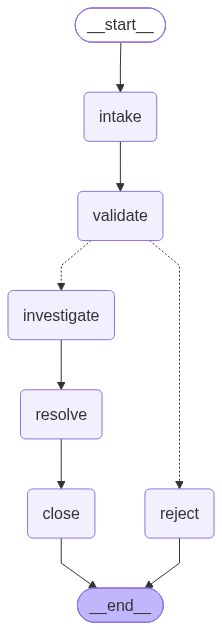

In [32]:
# YOUR TURN: draw the graph

display(Image(app.get_graph().draw_mermaid_png()))

In [33]:
# YOUR TURN: print the path of each result

for r in results:
    print(" → ".join(r["workflow_path"]))

intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → reject


---
## Step 6: Compare with LangChain [YOUR TURN]

Ask the same complaint with **one LLM call** (no graph, no lore). Then fill in the table.

In [35]:
# YOUR TURN: one LLM call

# Ask the first complaint directly without LangGraph
answer = llm.invoke([
    HumanMessage(content=test_complaints[0])
])

print(answer.content)

# Test the invalid complaint directly
invalid_answer = llm.invoke([
    HumanMessage(content=test_complaints[4])
])

print("\nInvalid complaint response:")
print(invalid_answer.content)

To predict when the Downside Up portal opens each day, you can follow these steps:

1. **Collect Data**: Record the opening times of the portal over several days. Note the date and the exact time it opens.

2. **Look for Patterns**: Analyze the data for any patterns or trends. Check if the opening times follow a specific schedule, such as opening at the same time on certain days of the week or if there are variations based on other factors.

3. **Consider External Factors**: Determine if there are any external factors that might influence the opening times, such as events, lunar cycles, or other occurrences.

4. **Create a Prediction Model**: Based on the patterns you've identified, create a simple model to predict future opening times. This could be as straightforward as averaging the times or using more complex statistical methods if you have enough data.

5. **Test Your Predictions**: Once you have a model, test it against actual opening times for a few days to see how accurate it i


| Question | LangGraph | One LLM call |
|---|---|---|
| Same answer every run? | Not guaranteed; LLM wording may vary | Not guaranteed; responses may vary |
| Invalid complaint rejected? | Yes, rejected by validation | No, generated a humorous complaint instead |
| Path visible? | Yes, all workflow nodes are recorded | No structured workflow path |
| Source of each claim? | LORE evidence is stored and inspectable | No provided evidence or source |
| Best for which client case? | Controlled processes requiring validation and traceability | Open-ended questions and creative conversations |


---
## Extensions [OPTIONAL]

- Parallel investigation
- Retry logic
- Human approval before `resolve`
- Save state with a checkpointer

In [ ]:
# YOUR TURN (optional)

# TODO

---
## ✅ Write `lab_proof.md` [YOUR TURN]

```markdown
# Lab Proof: NormalObjects Complaint Processor

## 1. What I built
## 2. Query
## 3. Evidence (workflow path + log lines + lore used)
## 4. Final output
## 5. Trace (which claim comes from which lore line?)
## 6. Failure or limitation
## 7. LangGraph vs. one LLM call
```

**Before you submit:**
- [ ] No API keys or `.env`
- [ ] Only lab files
- [ ] `lab_proof.md` is the entry point

---
### Troubleshooting

| Problem | Fix |
|---|---|
| Workflow stops at a node | Check node return values and edges |
| Routing doesn't work | Routing function must return a name from the mapping |
| State not updating | Return the updated fields; keys must exist in the state |
| Valid complaint rejected | Print the raw category (dot, capital, newline?) |
| `draw_mermaid_png()` fails | Use `print(app.get_graph().draw_mermaid())` |